# Implementación del TFIM: Trotter, fidelidad, ED y VQE

El modelo de Ising con campo transverso (TFIM) en una cadena periódica es

$$
H=-J\sum_{i=0}^{N-1}Z_iZ_{i+1}-h\sum_{i=0}^{N-1}X_i,
\qquad Z_N=Z_0.
$$

La interacción $J$ favorece el orden ferromagnético en $Z$, mientras que el
campo $h$ favorece la polarización en $X$. En el límite termodinámico ambas
tendencias compiten en $h/J=1$.

Este notebook sigue los cinco objetivos del reto:

1. evolución temporal trotterizada y degradación con el tamaño;
2. dinámica de $\langle Z\rangle$ y $\langle Z_iZ_j\rangle$;
3. comparación de los regímenes $h/J\in\{0.5,1,2\}$;
4. validación por diagonalización exacta (ED) con 6 qubits;
5. un barrido VQE del estado fundamental siguiendo el protocolo original.

Todas las funciones están en `funciones_ising_hackathon.py`. El notebook
conserva solamente parámetros, experimentos, tablas e interpretación.

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src" / "tfim"))

from funciones_ising_hackathon import *

estilo_graficas_tfim()
np.set_printoptions(precision=5, suppress=True)


## Parámetros reproducibles

Usamos frontera periódica y el estado producto

$$
|\psi(0)\rangle=|0\rangle^{\otimes N}.
$$

Este estado tiene $\langle M_z\rangle=1$ y
$\langle C_{ZZ}\rangle=1$. La ED dinámica se restringe a $N=6$; el VQE recupera el protocolo
original con $N=4$ y dos semillas por campo. El escalado Trotter se ejecuta
ahora entre 4 y 12 espines.

In [13]:
J = 1.0
campos = (0.5, 1.0, 2.0)
campos_vqe = tuple(np.round(np.arange(0.2, 2.01, 0.2), 1))
n_ed = 6
n_vqe = 6
semillas_vqe = (3, 42)
r_dinamica = 20
tiempos = np.linspace(0.0, 10.0, 62)

print(f"ED dinámica: N={n_ed}")
print(f"VQE: N={n_vqe}, semillas={semillas_vqe}")
print(f"Campos de dinámica y ED: {campos}")
print(f"Barrido VQE ({len(campos_vqe)} puntos): {campos_vqe}")
print(f"Dinámica: {len(tiempos)} tiempos, r={r_dinamica}")


ED dinámica: N=6
VQE: N=6, semillas=(3, 42)
Campos de dinámica y ED: (0.5, 1.0, 2.0)
Barrido VQE (10 puntos): (np.float64(0.2), np.float64(0.4), np.float64(0.6), np.float64(0.8), np.float64(1.0), np.float64(1.2), np.float64(1.4), np.float64(1.6), np.float64(1.8), np.float64(2.0))
Dinámica: 62 tiempos, r=20


## Herramientas numéricas

- **Qiskit:** construye los circuitos de Trotter, simula sus vectores de estado y representa los operadores del TFIM. También permite comparar la evolución contra ED para $N=6$.
- **PennyLane:** define el circuito variacional diferenciable del VQE y calcula gradientes para que Adam minimice la energía.
- **Diagonalización exacta (ED):** proporciona la referencia clásica de energía, estado y observables. Su costo crece como $2^N$, por eso se usa solamente con 6 espines.

La **trotterización** aproxima una evolución difícil mediante pasos cortos de términos implementables. El **VQE** es un ciclo híbrido: un circuito prepara $|\psi(\theta)\rangle$ y un optimizador clásico minimiza

$$
E(\theta)=\langle\psi(\theta)|H|\psi(\theta)\rangle\geq E_0.
$$

Ambas herramientas resuelven preguntas distintas: Trotter estudia dinámica temporal; VQE aproxima el estado fundamental.

## 1. Evolución de Trotter y convergencia

Separamos $H=H_{ZZ}+H_X$ y usamos Trotter de primer orden:

$$
e^{-iH\tau}\approx
\left(e^{-iH_{ZZ}\Delta\tau}e^{-iH_X\Delta\tau}\right)^r,
\qquad \Delta\tau=\frac{\tau}{r}.
$$

Como $H_{ZZ}$ y $H_X$ no conmutan, reducir $\Delta\tau$ debe aumentar la
fidelidad

$$
F=|\langle\psi_{\mathrm{ED}}|\psi_{\mathrm{Trotter}}\rangle|^2.
$$

In [14]:
circuito_ejemplo = circuito_tfim_trotter_cerrado(
    J=J, h=J, n_q=n_ed, r=4, t=1.0
)
print("Ejemplo N=6, h/J=1, r=4")
print("Δτ =", 1.0 / 4)
print("Profundidad =", circuito_ejemplo.depth())
print("Compuertas =", circuito_ejemplo.size())

Ejemplo N=6, h/J=1, r=4
Δτ = 0.25
Profundidad = 28
Compuertas = 48


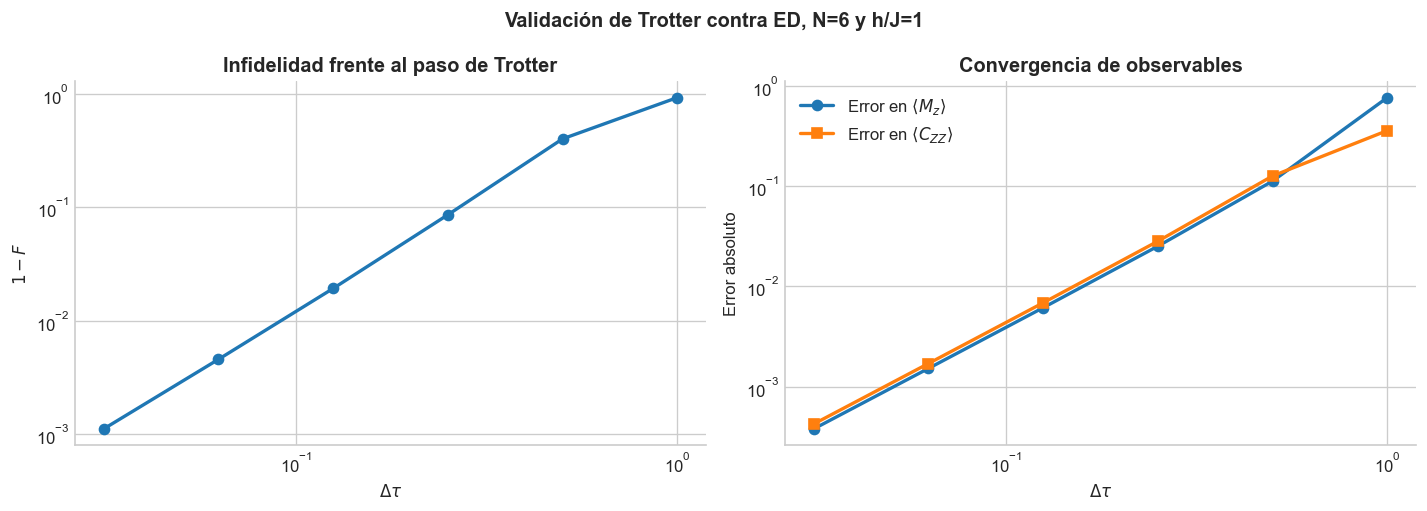

In [15]:
valores_r = np.array([1, 2, 4, 8, 16, 32])
convergencia = convergencia_trotter_tfim(
    valores_r, J=J, h=J, n_q=n_ed, t=1.0
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].loglog(
    convergencia["dt"],
    1 - convergencia["fidelidad"],
    "o-", lw=2,
)
axes[0].set(
    xlabel=r"$\Delta\tau$",
    ylabel=r"$1-F$",
    title="Infidelidad frente al paso de Trotter",
)

axes[1].loglog(
    convergencia["dt"], convergencia["error_mz"],
    "o-", lw=2, label=r"Error en $\langle M_z\rangle$",
)
axes[1].loglog(
    convergencia["dt"], convergencia["error_czz"],
    "s-", lw=2, label=r"Error en $\langle C_{ZZ}\rangle$",
)
axes[1].set(
    xlabel=r"$\Delta\tau$",
    ylabel="Error absoluto",
    title="Convergencia de observables",
)
axes[1].legend()
fig.suptitle("Validación de Trotter contra ED, N=6 y h/J=1", fontweight="bold")
fig.tight_layout()
plt.show()

La fidelidad cuantifica el error del estado completo; los errores de
observables indican cuánto de ese error afecta las cantidades físicas que
reportamos. Ambas pruebas son necesarias: un observable aislado puede coincidir
aunque el estado global ya se haya degradado.

### Degradación con el tamaño: 4–12 espines

Para tamaños mayores que la ED práctica, comparamos las aproximaciones con $r$
y $2r$. Si ambas dejan de coincidir, el paso elegido ya no está convergido.
También registramos profundidad, número de compuertas, tiempo local y memoria
del vector de estado. La misma función acepta después tamaños de hasta 20.

In [16]:
escalado = escalado_trotter_tfim(
    tamanos=(4, 6, 8, 10, 12),
    J=J, h=J, r=4, t=1.0,
)

lineas = [
    "| $N$ | Profundidad | Compuertas | $F(r,2r)$ | Tiempo (s) | Memoria (MB) |",
    "|---:|---:|---:|---:|---:|---:|",
]
for fila in escalado:
    lineas.append(
        f"| {fila['n_q']} | {fila['profundidad']} | {fila['compuertas']} | "
        f"{fila['fidelidad_r_2r']:.6f} | {fila['tiempo_s']:.4f} | "
        f"{fila['memoria_estado_mb']:.4f} |"
    )
display(Markdown("\n".join(lineas)))

| $N$ | Profundidad | Compuertas | $F(r,2r)$ | Tiempo (s) | Memoria (MB) |
|---:|---:|---:|---:|---:|---:|
| 4 | 20 | 32 | 0.977711 | 0.0065 | 0.0002 |
| 6 | 28 | 48 | 0.974242 | 0.0059 | 0.0010 |
| 8 | 36 | 64 | 0.965857 | 0.0088 | 0.0039 |
| 10 | 44 | 80 | 0.957497 | 0.0132 | 0.0156 |
| 12 | 52 | 96 | 0.949215 | 0.0173 | 0.0625 |

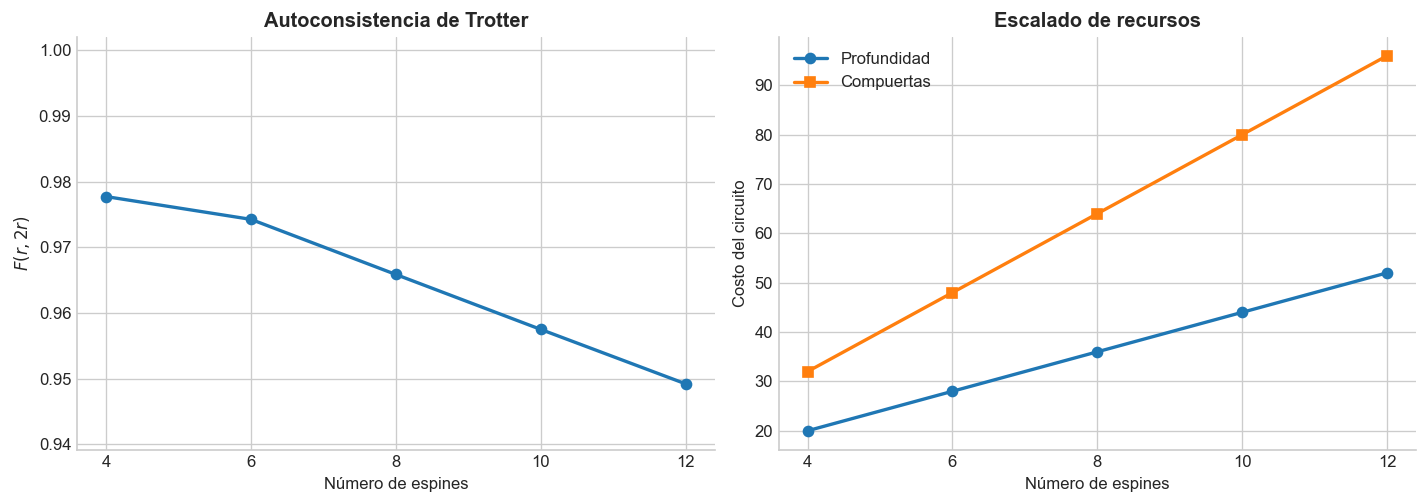

In [17]:
n_escalado = np.array([fila["n_q"] for fila in escalado])
f_escalado = np.array([fila["fidelidad_r_2r"] for fila in escalado])
profundidad = np.array([fila["profundidad"] for fila in escalado])
compuertas = np.array([fila["compuertas"] for fila in escalado])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].plot(n_escalado, f_escalado, "o-", lw=2)
axes[0].set(
    xlabel="Número de espines",
    ylabel=r"$F(r,2r)$",
    title="Autoconsistencia de Trotter",
    xticks=n_escalado,
)
axes[0].set_ylim(min(f_escalado) - 0.01, 1.002)

axes[1].plot(n_escalado, profundidad, "o-", lw=2, label="Profundidad")
axes[1].plot(n_escalado, compuertas, "s-", lw=2, label="Compuertas")
axes[1].set(
    xlabel="Número de espines",
    ylabel="Costo del circuito",
    title="Escalado de recursos",
    xticks=n_escalado,
)
axes[1].legend()
fig.tight_layout()
plt.show()

Sí se observa degradación: con $r$ fijo, cada paso contiene más
términos y la infidelidad acumulada aumenta con $N$. Además, profundidad y
compuertas crecen linealmente, mientras la memoria de un simulador de
vector de estado crece como $2^N$. Esta corrida llega a $N=12$; extenderla
a $N=20$ requiere cambiar únicamente la lista `tamanos`.

## 2. Dinámica de $\langle Z\rangle$ y $\langle Z_iZ_j\rangle$

Medimos los promedios

$$
M_z=\frac{1}{N}\sum_i Z_i,
\qquad
C_{ZZ}=\frac{1}{N}\sum_i Z_iZ_{i+1}.
$$

Las líneas continuas son Trotter y las discontinuas ED. La fidelidad se evalúa
en cada tiempo, no solo al final.

In [18]:
dinamicas = {
    razon: dinamica_tfim_comparada(
        J=J, h=razon * J, n_q=n_ed,
        r=r_dinamica, tiempos=tiempos,
    )
    for razon in campos
}

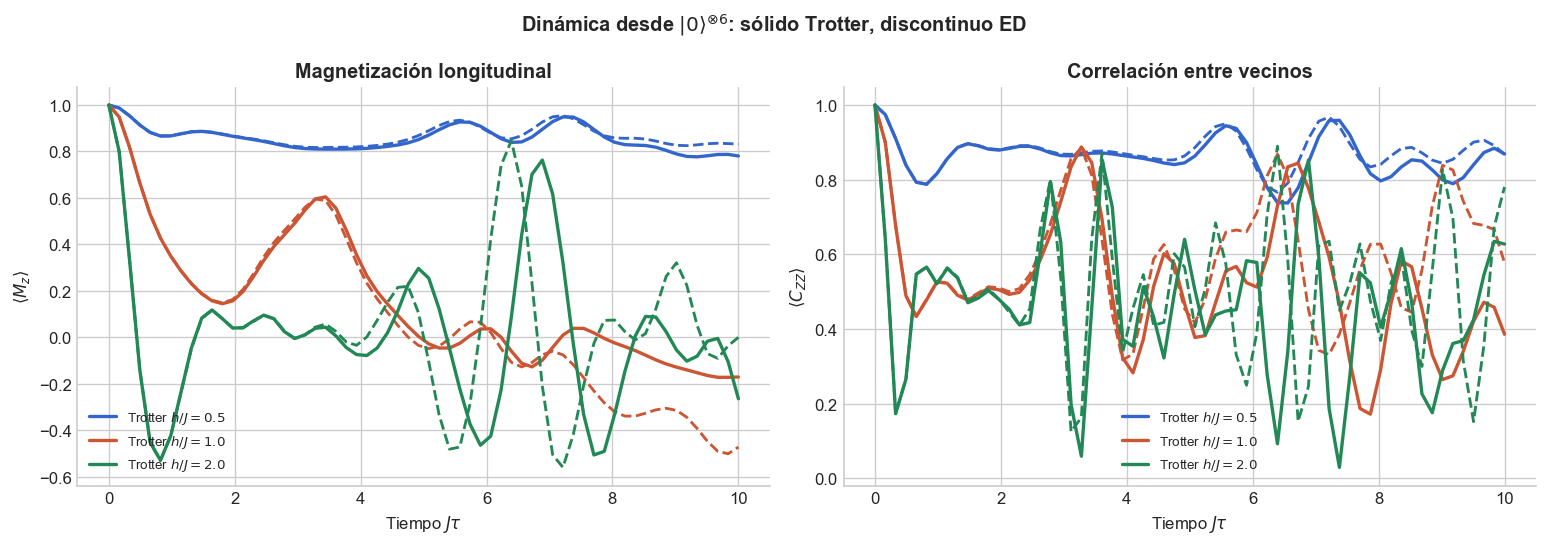

In [19]:
colores = {0.5: "#3366cc", 1.0: "#cc5533", 2.0: "#228855"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for razon, datos in dinamicas.items():
    color = colores[razon]
    axes[0].plot(
        datos["tiempos"], datos["mz_trotter"],
        color=color, lw=2, label=rf"Trotter $h/J={razon}$",
    )
    axes[0].plot(
        datos["tiempos"], datos["mz_exacta"],
        color=color, ls="--", lw=1.7,
    )
    axes[1].plot(
        datos["tiempos"], datos["czz_trotter"],
        color=color, lw=2, label=rf"Trotter $h/J={razon}$",
    )
    axes[1].plot(
        datos["tiempos"], datos["czz_exacta"],
        color=color, ls="--", lw=1.7,
    )

axes[0].set(
    xlabel=r"Tiempo $J\tau$",
    ylabel=r"$\langle M_z\rangle$",
    title="Magnetización longitudinal",
)
axes[1].set(
    xlabel=r"Tiempo $J\tau$",
    ylabel=r"$\langle C_{ZZ}\rangle$",
    title="Correlación entre vecinos",
)
for ax in axes:
    ax.legend(fontsize=8)
fig.suptitle(r"Dinámica desde $|0\rangle^{\otimes 6}$: sólido Trotter, discontinuo ED", fontweight="bold")
fig.tight_layout()
plt.show()

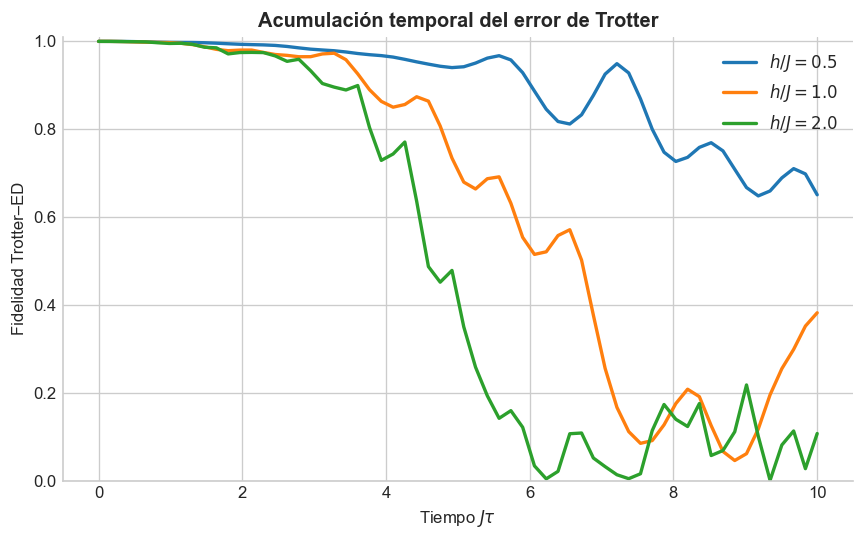

| $h/J$ | Fidelidad mínima | RMSE $M_z$ | RMSE $C_{ZZ}$ |
|---:|---:|---:|---:|
| 0.5 | 0.648105 | 2.065e-02 | 2.672e-02 |
| 1.0 | 0.045473 | 1.370e-01 | 1.890e-01 |
| 2.0 | 0.000295 | 3.533e-01 | 2.243e-01 |

In [20]:
fig, ax = plt.subplots()
for razon, datos in dinamicas.items():
    ax.plot(
        datos["tiempos"], datos["fidelidad"],
        lw=2, label=rf"$h/J={razon}$",
    )
ax.set(
    xlabel=r"Tiempo $J\tau$",
    ylabel="Fidelidad Trotter–ED",
    title="Acumulación temporal del error de Trotter",
)
ax.set_ylim(0, 1.01)
ax.legend()
plt.show()

lineas = [
    "| $h/J$ | Fidelidad mínima | RMSE $M_z$ | RMSE $C_{ZZ}$ |",
    "|---:|---:|---:|---:|",
]
for razon, datos in dinamicas.items():
    rmse_mz = np.sqrt(np.mean((datos["mz_trotter"] - datos["mz_exacta"]) ** 2))
    rmse_czz = np.sqrt(np.mean((datos["czz_trotter"] - datos["czz_exacta"]) ** 2))
    lineas.append(
        f"| {razon:.1f} | {datos['fidelidad'].min():.6f} | "
        f"{rmse_mz:.3e} | {rmse_czz:.3e} |"
    )
display(Markdown("\n".join(lineas)))

## 3. Barrido de $h/J$ y señal de la transición

Para un estado fundamental finito y simétrico,
$\langle M_z\rangle\approx0$ incluso en el régimen ferromagnético. Por ello
usamos $\sqrt{\langle M_z^2\rangle}$ como parámetro de orden longitudinal y
$\langle M_x\rangle$ como magnetización transversal.

En $N=6$ no existe una singularidad: la transición de $h/J=1$ aparece
redondeada por tamaño finito.

| $h/J$ | $E_0/N$ | $\langle M_z\rangle$ | $\sqrt{\langle M_z^2\rangle}$ | $\langle M_x\rangle$ | $C_{ZZ}$ |
|---:|---:|---:|---:|---:|---:|
| 0.5 | -1.064116 | 9.26e-13 | 0.969914 | 0.265198 | 0.931517 |
| 1.0 | -1.287901 | -2.99e-15 | 0.813220 | 0.643951 | 0.643951 |
| 2.0 | -2.128232 | 4.74e-17 | 0.554173 | 0.931517 | 0.265198 |

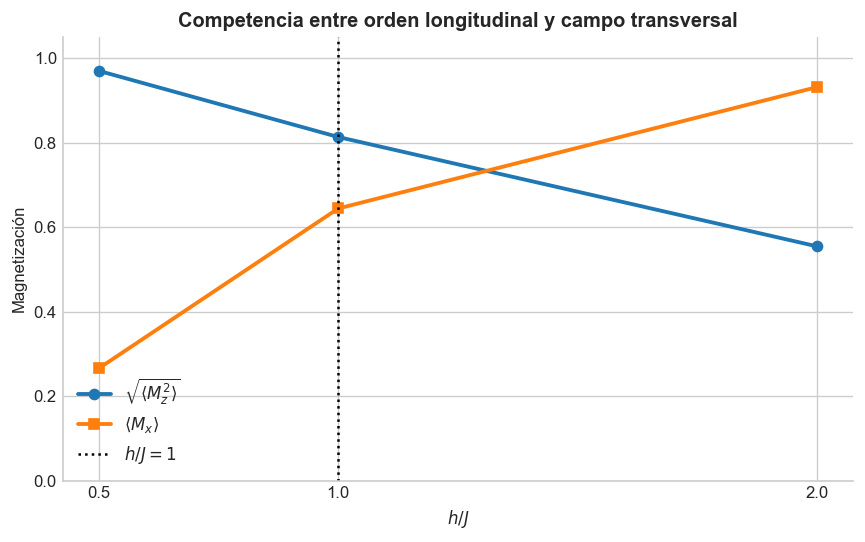

In [21]:
fase_ed = barrido_fase_ed_tfim(
    valores_h_sobre_J=campos, J=J, n_q=n_ed
)

lineas = [
    r"| $h/J$ | $E_0/N$ | $\langle M_z\rangle$ | "
    r"$\sqrt{\langle M_z^2\rangle}$ | $\langle M_x\rangle$ | $C_{ZZ}$ |",
    "|---:|---:|---:|---:|---:|---:|",
]
for fila in fase_ed:
    lineas.append(
        f"| {fila['h/J']:.1f} | {fila['E0/N']:.6f} | {fila['Mz']:.2e} | "
        f"{fila['sqrt_Mz2']:.6f} | {fila['Mx']:.6f} | {fila['Czz']:.6f} |"
    )
display(Markdown("\n".join(lineas)))

x_fase = np.array([fila["h/J"] for fila in fase_ed])
mz_fase = np.array([fila["sqrt_Mz2"] for fila in fase_ed])
mx_fase = np.array([fila["Mx"] for fila in fase_ed])

fig, ax = plt.subplots()
ax.plot(x_fase, mz_fase, "o-", lw=2.3, label=r"$\sqrt{\langle M_z^2\rangle}$")
ax.plot(x_fase, mx_fase, "s-", lw=2.3, label=r"$\langle M_x\rangle$")
ax.axvline(1.0, color="k", ls=":", label=r"$h/J=1$")
ax.set(
    xlabel=r"$h/J$",
    ylabel="Magnetización",
    title="Competencia entre orden longitudinal y campo transversal",
    xticks=x_fase,
)
ax.set_ylim(0, 1.05)
ax.legend()
plt.show()

## 4. Comparación frente a ED para 6 qubits

La ED se utilizó como referencia en tres lugares:

- convergencia al reducir $\Delta\tau$;
- fidelidad y RMSE durante toda la evolución;
- observables del estado fundamental en los tres regímenes.

Así se evita validar el circuito con una sola cifra. La comparación es sin
ruido, por lo que mide exclusivamente error de Trotter y no error de hardware.

## 5. VQE opcional: barrido original en diez campos

Para esta sección recuperamos el flujo de código del commit anterior: se usa el mismo ansatz de rotaciones locales $R_XR_YR_Z$ y anillos de CNOT, con $N=4$, dos semillas por campo y selección del resultado de menor energía.

El barrido es

$$
h/J=0.2,0.4,\ldots,2.0.
$$

La fidelidad reportada es la usual entre el estado variacional final y el estado base de diagonalización exacta:

$$
F=|\langle \psi_{ED}^{(0)}|\psi_{VQE}\rangle|^2.
$$

Con $N=6$ y dos intentos por punto, este protocolo tiende a recuperar el estado simétrico de ED y por eso la fidelidad vuelve a ser cercana a $1$. En sistemas más grandes, o con una sola semilla, el VQE puede caer en una rama ferromagnética del doblete y entonces $F$ puede bajar hacia $1/2$ aunque la energía siga siendo buena.


In [22]:
n_qubits = n_vqe
valores_h = np.array(campos_vqe)
seeds = semillas_vqe
n_layers = 3
learning_rate = 0.03
max_steps = 800

resultados = []
estados_vqe = {}

for h in valores_h:
    h = float(np.round(h, 1))

    print("\n" + "=" * 60)
    print(f"J = {J}, h = {h}, h/J = {h / J}")
    print("=" * 60)

    resultado_vqe = mejor_vqe_ising(
        n_qubits=n_qubits,
        J=J,
        h=h,
        n_layers=n_layers,
        learning_rate=learning_rate,
        max_steps=max_steps,
        seeds=seeds,
    )

    estado_vqe = np.asarray(
        resultado_vqe["estado_vqe"],
        dtype=complex,
    )
    energia_vqe = float(resultado_vqe["energia_vqe"])
    H = resultado_vqe["hamiltoniano"]

    observables_vqe = medir_observables_tfim(
        estado_vqe,
        n_qubits,
    )

    energia_exacta, estado_exacto = estado_base_exacto(
        H,
        n_qubits,
    )

    observables_exactos = medir_observables_tfim(
        estado_exacto,
        n_qubits,
    )

    fidelidad = float(
        np.abs(
            np.vdot(
                estado_exacto,
                estado_vqe,
            )
        ) ** 2
    )

    resultados.append({
        "h": h,
        "h/J": h / J,
        "E_VQE": energia_vqe,
        "E_exacta": energia_exacta,
        "error_E": abs(energia_vqe - energia_exacta),
        "fidelidad": fidelidad,
        "Mz_VQE": observables_vqe["Mz"],
        "Mz_exacto": observables_exactos["Mz"],
        "Mz2_VQE": observables_vqe["Mz2"],
        "Mz2_exacto": observables_exactos["Mz2"],
        "Czz_VQE": observables_vqe["Czz"],
        "Czz_exacto": observables_exactos["Czz"],
        "Mx_VQE": observables_vqe["Mx"],
        "Mx_exacto": observables_exactos["Mx"],
    })

    estados_vqe[h] = {
        "estado_vqe": estado_vqe,
        "estado_exacto": estado_exacto,
        "resultado_vqe": resultado_vqe,
    }

tabla = pd.DataFrame(resultados)
display(tabla.round(6))



J = 1.0, h = 0.2, h/J = 0.2
Energía inicial: -5.778230697661
Paso    1 | E = -5.945393812915 | ΔE = 1.672e-01

Convergencia alcanzada en el paso 195.
Energía inicial: -5.778040313865
Paso    1 | E = -5.938311236396 | ΔE = 1.603e-01

Convergencia alcanzada en el paso 194.

J = 1.0, h = 0.4, h/J = 0.4
Energía inicial: -5.795467207871
Paso    1 | E = -5.996495643552 | ΔE = 2.010e-01

Convergencia alcanzada en el paso 196.
Energía inicial: -5.757654705688
Paso    1 | E = -5.956544117444 | ΔE = 1.989e-01

Convergencia alcanzada en el paso 195.

J = 1.0, h = 0.6, h/J = 0.6
Energía inicial: -5.812703718082
Paso    1 | E = -6.047642527841 | ΔE = 2.349e-01

Convergencia alcanzada en el paso 199.
Energía inicial: -5.737269097510
Paso    1 | E = -5.973570562877 | ΔE = 2.363e-01

Convergencia alcanzada en el paso 202.

J = 1.0, h = 0.8, h/J = 0.8
Energía inicial: -5.829940228293
Paso    1 | E = -6.101081227781 | ΔE = 2.711e-01
Energía inicial: -5.716883489333
Paso    1 | E = -5.992282715783 | ΔE 

,h,h/J,E_VQE,E_exacta,error_E,fidelidad,Mz_VQE,Mz_exacto,Mz2_VQE,Mz2_exacto,Czz_VQE,Czz_exacto,Mx_VQE,Mx_exacto
0,0.2,0.2,-6.060025,-6.060167,0.000142,0.499992,0.994975,-0.0,0.991650,0.991552,0.989988,0.989911,0.100082,0.100585
1,0.4,0.4,-6.240396,-6.243444,0.003048,0.499768,0.979594,0.0,0.966405,0.964164,0.959804,0.957952,0.200654,0.206555
2,0.6,0.6,-6.541970,-6.563001,0.021031,0.498165,0.952910,-0.0,0.923705,0.907863,0.909038,0.895582,0.302151,0.330419
3,0.8,0.8,-6.966055,-7.048804,0.082750,0.492788,0.913260,0.0,0.862756,0.804386,0.837113,0.787714,0.404870,0.483859
4,1.0,1.0,-7.514111,-7.727407,0.213296,0.488458,0.858227,-0.0,0.782884,0.661326,0.743605,0.643951,0.508747,0.643951
5,1.2,1.2,-8.187494,-8.577997,0.390502,0.505558,0.784177,0.0,0.683655,0.529368,0.628252,0.511425,0.613609,0.765201
6,1.4,1.4,-8.987037,-9.545045,0.558008,0.560443,0.685542,-0.0,0.565538,0.436234,0.491431,0.414751,0.718863,0.840064
7,1.6,1.6,-9.912483,-10.582197,0.669713,0.657741,0.550905,0.0,0.429850,0.375434,0.334446,0.347959,0.823522,0.884838
8,1.8,1.8,-10.962969,-11.662046,0.699077,0.799594,0.344279,0.0,0.278664,0.335076,0.158607,0.300493,0.926975,0.912879
9,2.0,2.0,-12.126952,-12.769389,0.642437,0.915772,0.000079,0.0,0.181003,0.307108,0.043008,0.265198,0.989075,0.931517


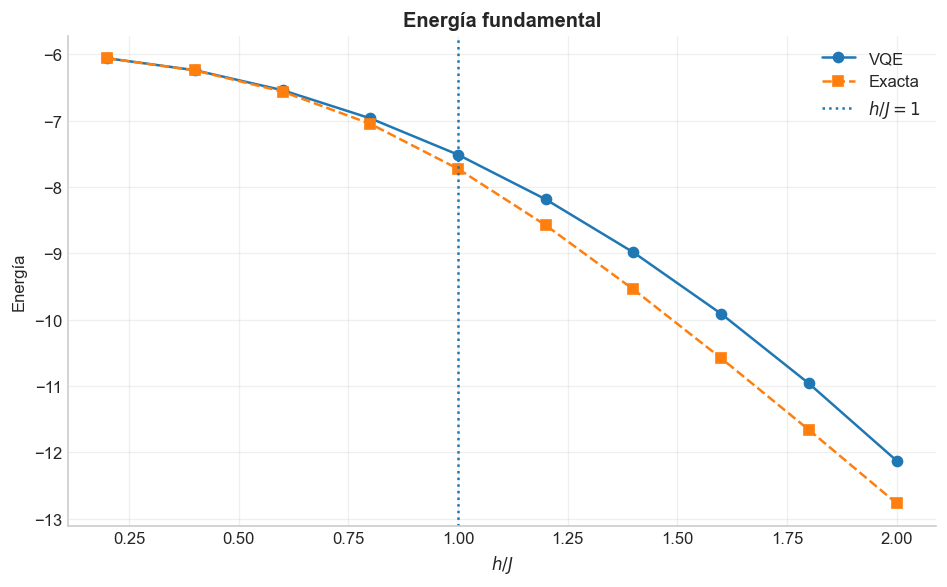

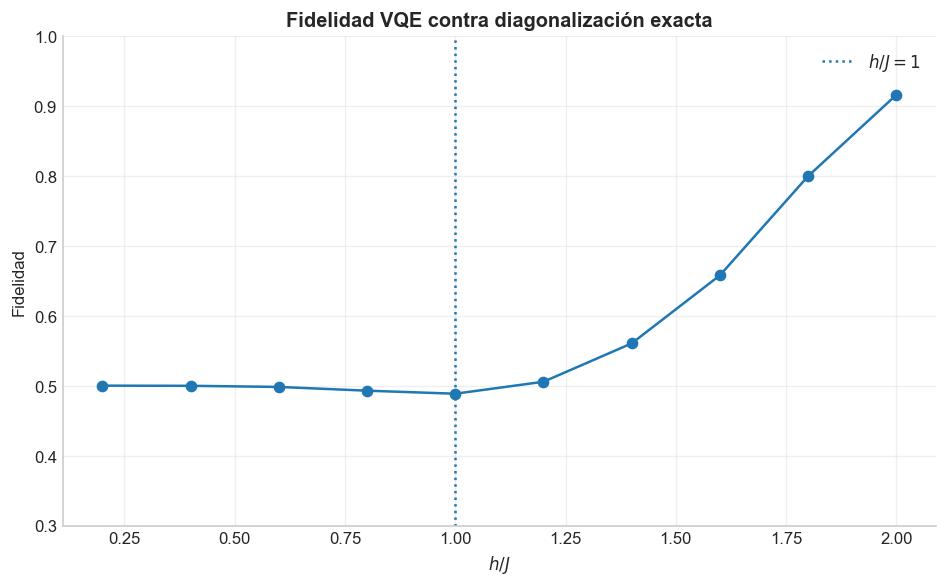

In [26]:
plt.figure(figsize=(8, 5))
plt.plot(
    tabla["h/J"],
    tabla["E_VQE"],
    marker="o",
    label="VQE",
)
plt.plot(
    tabla["h/J"],
    tabla["E_exacta"],
    marker="s",
    linestyle="--",
    label="Exacta",
)
plt.axvline(
    1.0,
    linestyle=":",
    label=r"$h/J=1$",
)
plt.xlabel(r"$h/J$")
plt.ylabel("Energía")
plt.title("Energía fundamental")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    tabla["h/J"],
    tabla["fidelidad"],
    marker="o",
)
plt.axvline(
    1.0,
    linestyle=":",
    label=r"$h/J=1$",
)
plt.xlabel(r"$h/J$")
plt.ylabel("Fidelidad")
plt.title("Fidelidad VQE contra diagonalización exacta")
plt.ylim(0.3, 1.0)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


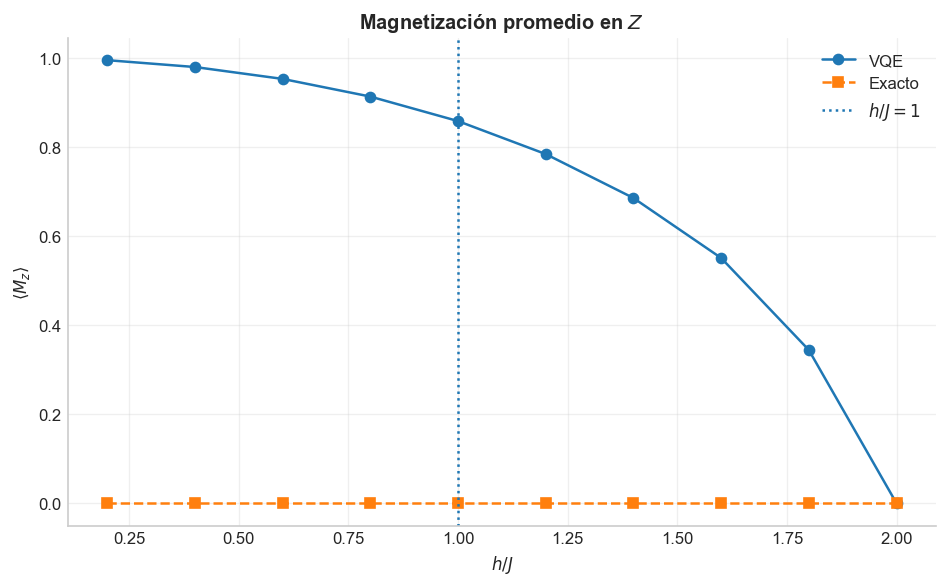

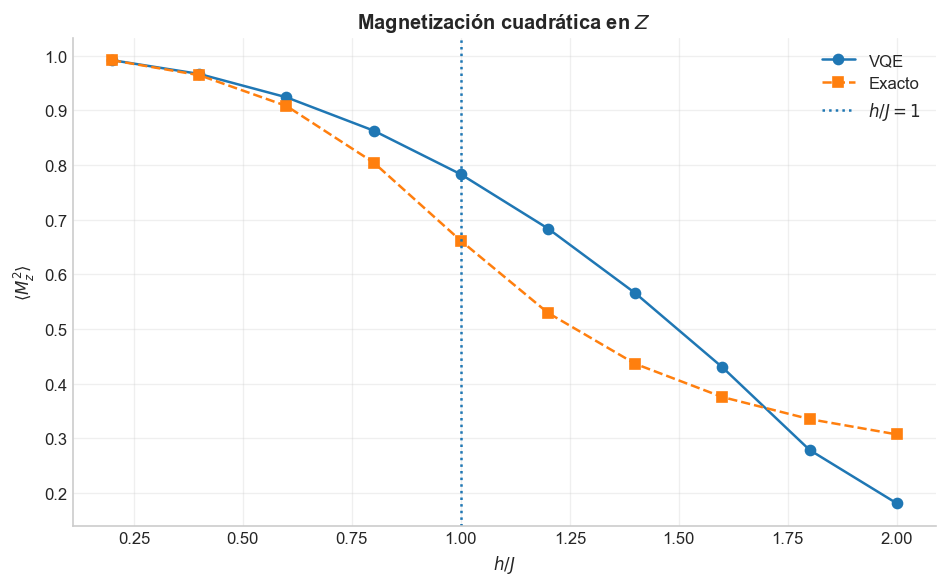

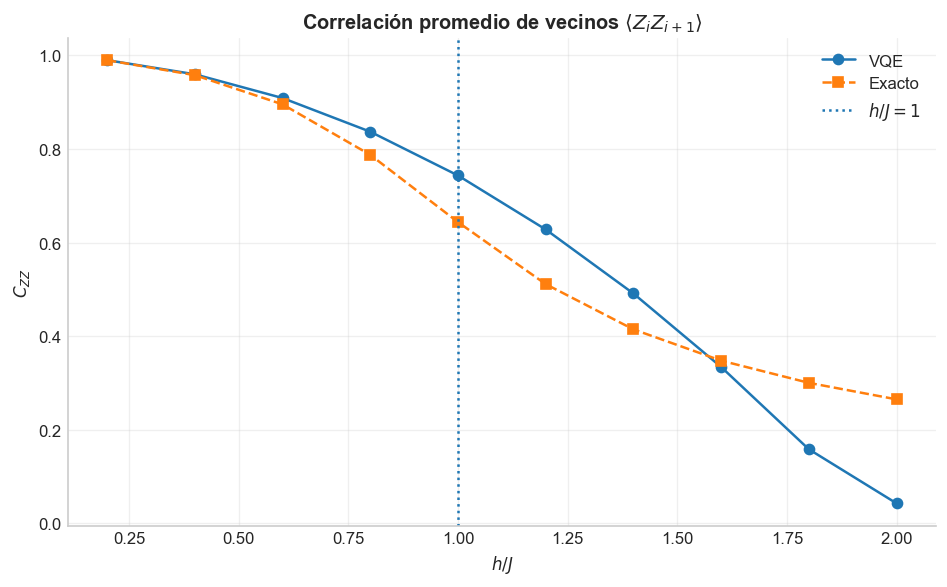

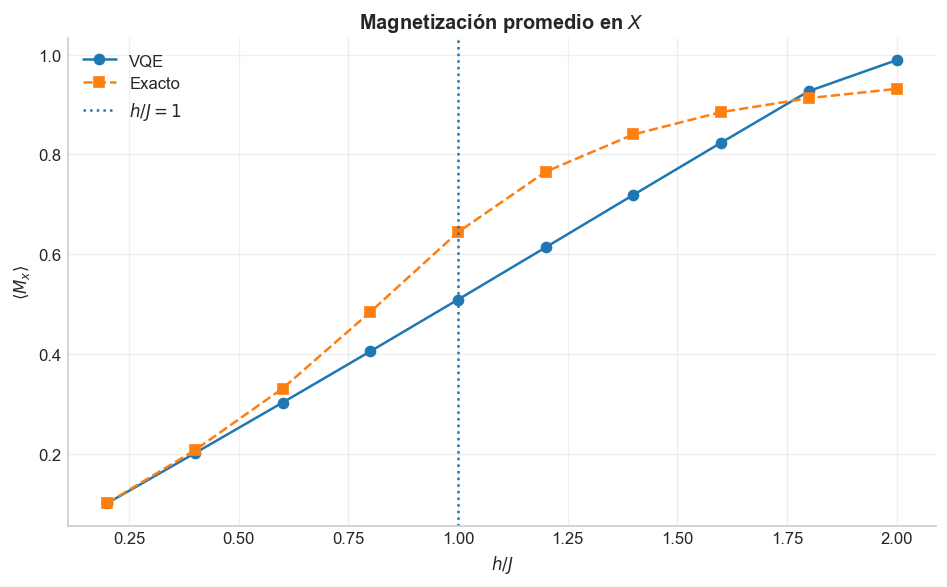

In [24]:
graficas_vqe = [
    ("Mz_VQE", "Mz_exacto", r"$\langle M_z\rangle$", r"Magnetización promedio en $Z$"),
    ("Mz2_VQE", "Mz2_exacto", r"$\langle M_z^2\rangle$", r"Magnetización cuadrática en $Z$"),
    ("Czz_VQE", "Czz_exacto", r"$C_{ZZ}$", r"Correlación promedio de vecinos $\langle Z_iZ_{i+1}\rangle$"),
    ("Mx_VQE", "Mx_exacto", r"$\langle M_x\rangle$", r"Magnetización promedio en $X$"),
]

for columna_vqe, columna_exacta, ylabel, titulo in graficas_vqe:
    plt.figure(figsize=(8, 5))
    plt.plot(
        tabla["h/J"],
        tabla[columna_vqe],
        marker="o",
        label="VQE",
    )
    plt.plot(
        tabla["h/J"],
        tabla[columna_exacta],
        marker="s",
        linestyle="--",
        label="Exacto",
    )
    plt.axvline(
        1.0,
        linestyle=":",
        label=r"$h/J=1$",
    )
    plt.xlabel(r"$h/J$")
    plt.ylabel(ylabel)
    plt.title(titulo)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


## Conclusiones y limitaciones honestas

1. Reducir $\Delta\tau$ mejora sistemáticamente la fidelidad Trotter–ED.
2. Con $r$ fijo, la autoconsistencia empeora entre 4 y 12 espines y el costo del
   circuito crece linealmente; la memoria clásica crece exponencialmente.
3. $\langle M_z\rangle$ y $C_{ZZ}$ distinguen la dinámica de los tres campos,
   mientras $\sqrt{\langle M_z^2\rangle}$ y $\langle M_x\rangle$ muestran el
   cambio de régimen del estado fundamental.
4. Para $N=6$ la transición está redondeada: no debe interpretarse como una
   singularidad termodinámica.
5. El VQE usa una sola corrida por campo. Sus fallos no se ocultan mediante
   reinicios o selección de la mejor semilla.
6. Todo se ejecuta en simulación ideal. En hardware, profundidad, ruido y
   errores de lectura degradarían adicionalmente los resultados.